# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** I Made Bagus Aristya Sadewa
- **Email:** bagusaristya3@gmail.com
- **ID Dicoding:** i_made_bagus_ariktcn

## Menentukan Pertanyaan Bisnis

Dataset **Bike Sharing** berisi catatan penyewaan sepeda sistem Capital Bikeshare (Washington D.C.) selama 2 tahun (2011–2012), dalam agregasi harian (`day.csv`) dan per jam (`hour.csv`). Pertanyaan bisnis disusun dengan metode **SMART**.

- **Pertanyaan 1:** Pada jam berapa saja (0–23) terjadi tiga jam puncak dengan rata-rata jumlah penyewaan sepeda tertinggi pada *hari kerja* dibandingkan *akhir pekan/hari libur* sepanjang 2011–2012, dan berapa selisih rata-ratanya pada jam puncak tersebut? Hasilnya dipakai operator untuk menjadwalkan redistribusi sepeda dan petugas lapangan.
- **Pertanyaan 2:** Berapa persentase penurunan rata-rata penyewaan harian pada cuaca buruk (hujan/salju ringan) dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011–2012? Hasilnya dipakai untuk menentukan strategi promosi dan jadwal perawatan armada.

**Uraian SMART:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Fokus pada jam puncak penyewaan, hari kerja vs akhir pekan/libur | Fokus pada pengaruh cuaca (`weathersit`) dan musim (`season`) terhadap penyewaan harian |
| Measurable | Rata-rata penyewaan per jam (`cnt`) dan selisihnya | Rata-rata penyewaan harian dan persentase penurunannya |
| Action-oriented | Menentukan jam redistribusi sepeda & penempatan petugas | Menentukan waktu promosi dan jadwal perawatan |
| Relevant | Ketersediaan sepeda pada jam sibuk adalah kunci layanan | Permintaan sangat dipengaruhi cuaca dan musim, sehingga penting untuk perencanaan operasional |
| Time-bound | Periode 2011–2012 | Periode 2011–2012 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## Data Wrangling

### Gathering Data

#### Load `day.csv` dan `hour.csv`

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)
day_df.head()

Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris (satu baris per hari, 2011–2012) dan `hour_df` berisi 17.379 baris (agregasi per jam). Keduanya memiliki kolom cuaca, musim, dan jumlah penyewaan (`casual`, `registered`, `cnt`); `hour_df` hanya menambahkan kolom `hr`.
- `day_df` dipakai untuk Pertanyaan 2 (level harian) dan `hour_df` untuk Pertanyaan 1 (level jam).

### Assessing Data

#### Memeriksa tipe data, missing value, dan duplikasi

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {name} ===")
    print("Missing value total :", df.isna().sum().sum())
    print("Data duplikat       :", df.duplicated().sum())
    print("Tipe data dteday    :", df["dteday"].dtype)
    print("cnt == casual + registered di semua baris:", (df["cnt"] == df["casual"] + df["registered"]).all())
    print()

=== day_df ===
Missing value total : 0
Data duplikat       : 0
Tipe data dteday    : str
cnt == casual + registered di semua baris: True

=== hour_df ===
Missing value total : 0
Data duplikat       : 0
Tipe data dteday    : str
cnt == casual + registered di semua baris: True



**Steps to Take:** Tidak ada missing value maupun duplikasi. Tipe `dteday` masih berupa string sehingga perlu diubah ke `datetime` pada tahap cleaning.

#### Memeriksa nilai tidak akurat (inaccurate value) pada kelembapan

In [5]:
print(day_df[["dteday", "hum"]].sort_values("hum").head(3))
print("\nJumlah hum = 0 di day_df :", (day_df["hum"] == 0).sum())
print("Jumlah hum = 0 di hour_df:", (hour_df["hum"] == 0).sum())

         dteday       hum
68   2011-03-10  0.000000
49   2011-02-19  0.187917
462  2012-04-07  0.254167

Jumlah hum = 0 di day_df : 1
Jumlah hum = 0 di hour_df: 22


**Steps to Take:** Kelembapan udara 0% hampir mustahil terjadi di Washington D.C. Pada `day_df` ada 1 hari (2011-03-10) dengan `hum = 0`. Nilai ini diperlakukan sebagai data tidak akurat dan akan diganti dengan hasil interpolasi dari hari-hari di sekitarnya. Pada `hour_df`, nilai `hum = 0` kemungkinan besar berasal dari hari yang sama (hari tanpa pencatatan), dan variabel kelembapan tidak dipakai untuk menjawab pertanyaan bisnis, sehingga cukup didokumentasikan.

#### Memeriksa nilai tidak konsisten (kode kategori numerik) dan skala kolom

In [6]:
print("season    :", sorted(day_df["season"].unique()))
print("weathersit:", sorted(day_df["weathersit"].unique()), "(hour_df:", sorted(hour_df["weathersit"].unique()), ")")
print("weekday   :", sorted(day_df["weekday"].unique()))
print("yr        :", sorted(day_df["yr"].unique()))
print("temp (ternormalisasi) min-max:", day_df["temp"].min(), "-", day_df["temp"].max())

season    : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
weathersit: [np.int64(1), np.int64(2), np.int64(3)] (hour_df: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] )
weekday   : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
yr        : [np.int64(0), np.int64(1)]
temp (ternormalisasi) min-max: 0.0591304 - 0.861667


**Steps to Take:** Kolom `season`, `weathersit`, `weekday`, `yr`, dan `mnth` masih berupa kode angka sehingga sulit dibaca pada visualisasi. Kodenya perlu diganti dengan label deskriptif. Kolom `temp` juga ternormalisasi (dibagi 41) sehingga perlu dikembalikan ke °C agar bisa diinterpretasikan.

#### Memeriksa outlier

cnt         -> outlier day_df:   0 | hour_df:  505
casual      -> outlier day_df:  44 | hour_df: 1192
registered  -> outlier day_df:   0 | hour_df:  680
windspeed   -> outlier day_df:  13 | hour_df:  342
hum         -> outlier day_df:   2 | hour_df:   22


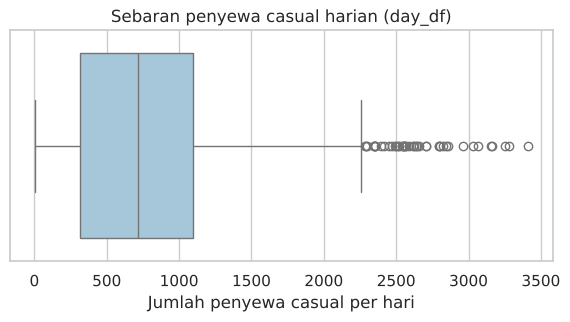

In [7]:
def count_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for col in ["cnt", "casual", "registered", "windspeed", "hum"]:
    print(f"{col:11s} -> outlier day_df: {count_outlier(day_df[col]):3d} | hour_df: {count_outlier(hour_df[col]):4d}")

plt.figure(figsize=(7, 3))
sns.boxplot(x=day_df["casual"], color="#9ecae1")
plt.title("Sebaran penyewa casual harian (day_df)")
plt.xlabel("Jumlah penyewa casual per hari")
plt.show()

**Steps to Take:** Outlier ditemukan pada `casual` dan `windspeed`. Outlier `casual` bukan kesalahan input, melainkan hari dengan lonjakan wisatawan/akhir pekan cerah (nilai riil). Karena itu outlier tidak dihapus, hanya didokumentasikan, supaya pola permintaan sebenarnya tidak hilang. Kolom `cnt` pada `day_df` tidak memiliki outlier.

#### Memeriksa kelengkapan jam pada `hour_df`

In [8]:
full_range = pd.date_range("2011-01-01 00:00", "2012-12-31 23:00", freq="h")
print("Jumlah jam seharusnya:", len(full_range))
print("Jumlah baris hour_df :", len(hour_df))
print("Jam yang tidak tercatat:", len(full_range) - len(hour_df))

Jumlah jam seharusnya: 17544
Jumlah baris hour_df : 17379
Jam yang tidak tercatat: 165


**Insight:** Ada 165 jam yang tidak tercatat di `hour_df`. Jam yang kosong umumnya berarti tidak ada penyewaan (mis. tengah malam), sehingga baris tidak ditambahkan. Rata-rata per jam dihitung dari jam yang tercatat saja, sehingga rata-rata jam sepi (dini hari) bisa sedikit lebih tinggi dari kondisi sebenarnya. Hal ini tidak memengaruhi penentuan jam puncak.

### Cleaning Data

#### Mengubah tipe data `dteday` menjadi datetime

In [9]:
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])
print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[us] datetime64[us]


#### Memperbaiki nilai kelembapan yang tidak akurat (`hum = 0`)

In [10]:
day_df["hum"] = day_df["hum"].replace(0, np.nan).interpolate()
print("hum = 0 di day_df setelah dibersihkan:", (day_df["hum"] == 0).sum())
print("Nilai hum 2011-03-10 setelah interpolasi:", round(day_df.loc[day_df["dteday"] == "2011-03-10", "hum"].iloc[0], 3))

# hour_df: kelembapan 0 pada jam yang sama diganti NaN lalu diinterpolasi
hour_df["hum"] = hour_df["hum"].replace(0, np.nan).interpolate()
print("hum = 0 di hour_df setelah dibersihkan:", (hour_df["hum"] == 0).sum())

hum = 0 di day_df setelah dibersihkan: 0
Nilai hum 2011-03-10 setelah interpolasi: 0.712
hum = 0 di hour_df setelah dibersihkan: 0


#### Mengganti kode kategori menjadi label dan mengembalikan skala suhu

In [11]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
year_map = {0: 2011, 1: 2012}

for df in (day_df, hour_df):
    df["season"] = df["season"].map(season_map)
    df["weathersit"] = df["weathersit"].map(weather_map)
    df["weekday"] = df["weekday"].map(weekday_map)
    df["yr"] = df["yr"].map(year_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    df["temp_celsius"] = df["temp"] * 41   # dataset menormalisasi dengan pembagi 41

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,day_type,temp_celsius
0,1,2011-01-01,Spring,2011,1,0,Sabtu,0,Berkabut/Berawan,0.344167,0.363625,0.805833,0.160446,331,654,985,Akhir Pekan/Libur,14.110847
1,2,2011-01-02,Spring,2011,1,0,Minggu,0,Berkabut/Berawan,0.363478,0.353739,0.696087,0.248539,131,670,801,Akhir Pekan/Libur,14.902598
2,3,2011-01-03,Spring,2011,1,0,Senin,1,Cerah,0.196364,0.189405,0.437273,0.248309,120,1229,1349,Hari Kerja,8.050924
3,4,2011-01-04,Spring,2011,1,0,Selasa,1,Cerah,0.200000,0.212122,0.590435,0.160296,108,1454,1562,Hari Kerja,8.200000
4,5,2011-01-05,Spring,2011,1,0,Rabu,1,Cerah,0.226957,0.229270,0.436957,0.186900,82,1518,1600,Hari Kerja,9.305237


**Insight:**
- Tipe tanggal sudah `datetime`, nilai `hum = 0` sudah diperbaiki, dan kode kategori sudah diganti label yang mudah dibaca.
- Dibuat kolom bantu `day_type` (Hari Kerja vs Akhir Pekan/Libur, berdasarkan `workingday`) dan `temp_celsius` (suhu dalam °C).
- Outlier `casual` sengaja dipertahankan karena merupakan nilai riil.

## Exploratory Data Analysis (EDA)

### Eksplorasi ringkasan statistik

In [12]:
day_df[["cnt", "casual", "registered", "temp_celsius", "hum", "windspeed"]].describe().round(2)

,cnt,casual,registered,temp_celsius,hum,windspeed
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,4504.35,848.18,3656.17,20.31,0.63,0.19
std,1937.21,686.62,1560.26,7.51,0.14,0.08
min,22.00,2.00,20.00,2.42,0.19,0.02
25%,3152.00,315.50,2497.00,13.82,0.52,0.13
50%,4548.00,713.00,3662.00,20.43,0.63,0.18
75%,5956.00,1096.00,4776.50,26.87,0.73,0.23
max,8714.00,3410.00,6946.00,35.33,0.97,0.51


In [13]:
print("Rata-rata penyewaan harian 2011:", round(day_df.loc[day_df["yr"] == 2011, "cnt"].mean(), 1))
print("Rata-rata penyewaan harian 2012:", round(day_df.loc[day_df["yr"] == 2012, "cnt"].mean(), 1))
print("Proporsi penyewa registered:", round(day_df["registered"].sum() / day_df["cnt"].sum() * 100, 1), "%")

Rata-rata penyewaan harian 2011: 3405.8
Rata-rata penyewaan harian 2012: 5599.9
Proporsi penyewa registered: 81.2 %


**Insight:**
- Rata-rata penyewaan harian mencapai sekitar 4.504 sepeda dengan variasi cukup besar (min sekitar 22, maks 8.714).
- Penyewaan tumbuh kuat dari 2011 ke 2012 (sekitar 3.406 menjadi 5.600 per hari).
- Sekitar 81% penyewa adalah pengguna *registered*.

### Eksplorasi Pertanyaan 1: pola penyewaan per jam

In [14]:
hourly = (hour_df.groupby(["day_type", "hr"])["cnt"].mean().unstack(0).round(1))
print("Rata-rata penyewaan per jam (seluruh hari):")
print(hour_df.groupby("day_type")["cnt"].mean().round(1))

print("\n3 jam puncak hari kerja:")
top_wd = hourly["Hari Kerja"].nlargest(3)
print(top_wd)
print("\n3 jam puncak akhir pekan/libur:")
top_we = hourly["Akhir Pekan/Libur"].nlargest(3)
print(top_we)

print("\nSelisih rata-rata pada jam puncak (hari kerja - akhir pekan/libur):")
print((hourly["Hari Kerja"] - hourly["Akhir Pekan/Libur"]).loc[top_wd.index].round(1))

Rata-rata penyewaan per jam (seluruh hari):
day_type
Akhir Pekan/Libur    181.4
Hari Kerja           193.2
Name: cnt, dtype: float64

3 jam puncak hari kerja:
hr
17    525.3
18    492.2
8     477.0
Name: Hari Kerja, dtype: float64

3 jam puncak akhir pekan/libur:
hr
13    372.7
12    366.3
14    364.6
Name: Akhir Pekan/Libur, dtype: float64

Selisih rata-rata pada jam puncak (hari kerja - akhir pekan/libur):
hr
17    201.8
18    211.1
8     371.3
dtype: float64


**Insight:**
- Hari kerja memiliki dua puncak, yaitu pagi hari (jam 8) dan sore hari (jam 17–18), yang sesuai dengan jam komuting. Puncak tertinggi pada jam 17 (sekitar 525 sepeda).
- Akhir pekan/libur memiliki satu puncak landai pada siang hari (jam 12–14, sekitar 365–373 sepeda), tanpa lonjakan jam sibuk.
- Pada jam 8, penyewaan hari kerja (sekitar 477) hampir 4,5 kali lipat akhir pekan (sekitar 106).

### Eksplorasi Pertanyaan 2: pengaruh cuaca dan musim

In [15]:
weather_stat = day_df.groupby("weathersit")["cnt"].agg(["count", "mean"]).round(1)
print(weather_stat)

clear_avg = weather_stat.loc["Cerah", "mean"]
bad_avg = weather_stat.loc["Hujan/Salju Ringan", "mean"]
print(f"\nPenurunan rata-rata penyewaan cuaca hujan/salju ringan vs cerah: {(clear_avg - bad_avg) / clear_avg * 100:.1f}%")

season_order = ["Spring", "Summer", "Fall", "Winter"]
season_stat = day_df.groupby("season")["cnt"].mean().reindex(season_order).round(1)
print("\nRata-rata penyewaan harian per musim:")
print(season_stat)

                    count    mean
weathersit                       
Berkabut/Berawan      247  4035.9
Cerah                 463  4876.8
Hujan/Salju Ringan     21  1803.3

Penurunan rata-rata penyewaan cuaca hujan/salju ringan vs cerah: 63.0%

Rata-rata penyewaan harian per musim:
season
Spring    2604.1
Summer    4992.3
Fall      5644.3
Winter    4728.2
Name: cnt, dtype: float64


**Insight:**
- Cuaca sangat memengaruhi permintaan. Rata-rata penyewaan saat cerah sekitar 4.877 per hari, turun menjadi sekitar 1.803 saat hujan/salju ringan, atau penurunan sekitar **63%**.
- Musim **Fall** memiliki rata-rata penyewaan tertinggi (sekitar 5.644) dan **Spring** terendah (sekitar 2.604).
- Kategori cuaca 4 (hujan/salju lebat) hanya muncul 3 kali di data per jam dan tidak ada di data harian, sehingga tidak dianalisis lebih jauh.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa puncak penyewaan terjadi pada hari kerja vs akhir pekan/libur?

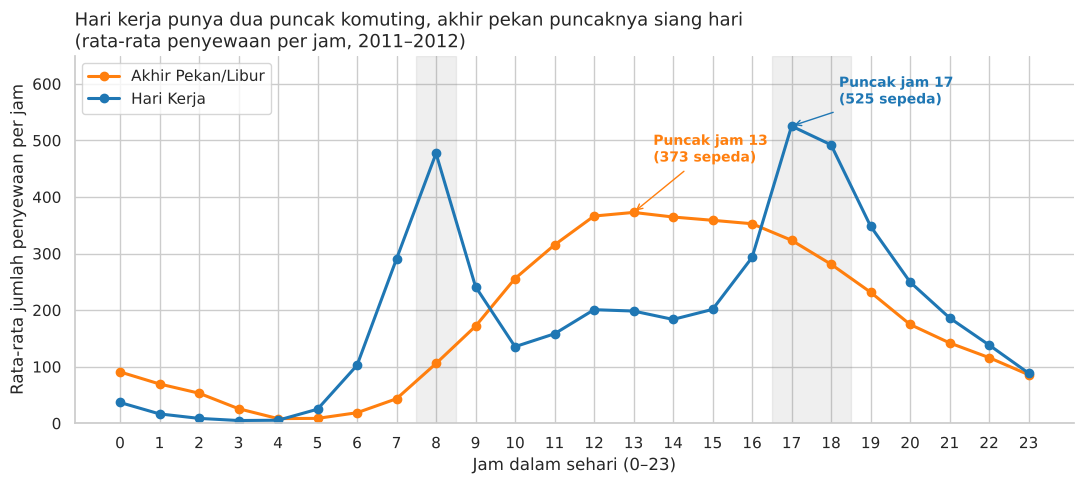

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = {"Hari Kerja": "#1f77b4", "Akhir Pekan/Libur": "#ff7f0e"}
for col in hourly.columns:
    ax.plot(hourly.index, hourly[col], marker="o", linewidth=2.2, label=col, color=colors[col])

# beri anotasi pada jam puncak
for col in hourly.columns:
    h_peak = hourly[col].idxmax()
    ax.annotate(f"Puncak jam {h_peak}\n({hourly[col].max():.0f} sepeda)",
                xy=(h_peak, hourly[col].max()),
                xytext=(h_peak + (1.2 if col == "Hari Kerja" else 0.5), hourly[col].max() + (40 if col == "Hari Kerja" else 90)),
                arrowprops=dict(arrowstyle="->", color=colors[col]), color=colors[col], fontsize=10, fontweight="bold")

ax.axvspan(7.5, 8.5, color="grey", alpha=0.12)
ax.axvspan(16.5, 18.5, color="grey", alpha=0.12)
ax.set_xticks(range(0, 24))
ax.set_ylim(0, 650)
ax.set_xlabel("Jam dalam sehari (0–23)")
ax.set_ylabel("Rata-rata jumlah penyewaan per jam")
ax.set_title("Hari kerja punya dua puncak komuting, akhir pekan puncaknya siang hari\n(rata-rata penyewaan per jam, 2011–2012)", loc="left", fontsize=13)
ax.legend(title=None, loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan:** Pada hari kerja terlihat dua puncak (jam 8 dan jam 17–18) yang selaras dengan jam berangkat dan pulang kerja. Pada akhir pekan/libur pola berubah menjadi satu puncak landai di siang hari. Area abu-abu menandai jam sibuk hari kerja.

### Pertanyaan 2: Bagaimana pengaruh cuaca dan musim terhadap rata-rata penyewaan harian?

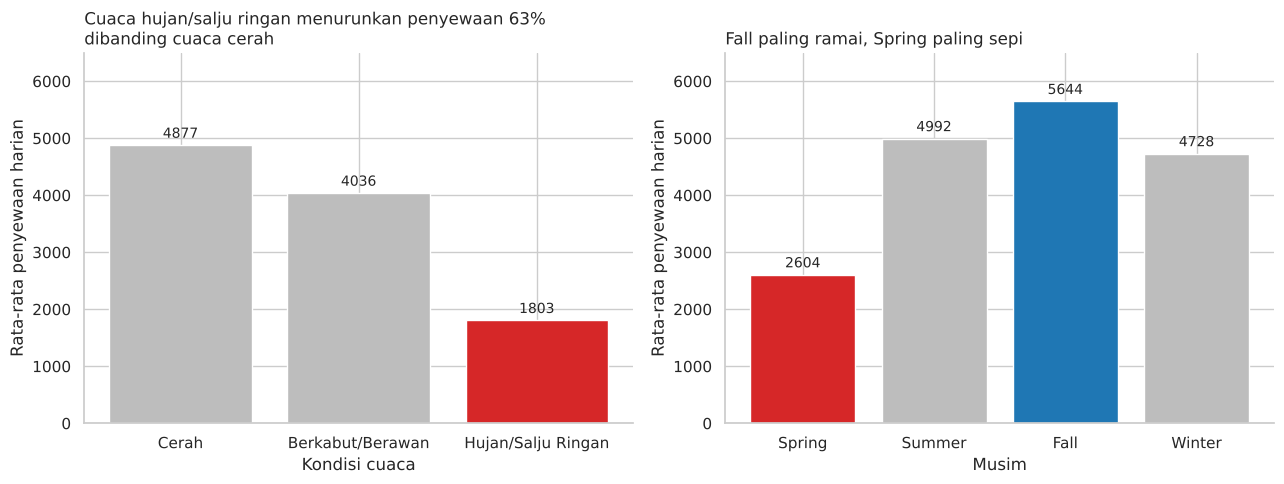

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel kiri: cuaca ---
w_order = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]
w_vals = weather_stat.loc[w_order, "mean"]
w_colors = ["#1f77b4", "#9ecae1", "#9ecae1"]
bars = axes[0].bar(w_order, w_vals, color=["#bdbdbd", "#bdbdbd", "#d62728"])
axes[0].bar_label(bars, fmt="%.0f", padding=3, fontsize=10)
axes[0].set_title(f"Cuaca hujan/salju ringan menurunkan penyewaan {((clear_avg-bad_avg)/clear_avg*100):.0f}%\ndibanding cuaca cerah", loc="left", fontsize=12)
axes[0].set_xlabel("Kondisi cuaca")
axes[0].set_ylabel("Rata-rata penyewaan harian")
axes[0].set_ylim(0, 6500)

# --- Panel kanan: musim ---
s_vals = season_stat.loc[season_order]
s_colors = ["#d62728" if s == s_vals.idxmin() else "#1f77b4" if s == s_vals.idxmax() else "#bdbdbd" for s in season_order]
bars = axes[1].bar(season_order, s_vals, color=s_colors)
axes[1].bar_label(bars, fmt="%.0f", padding=3, fontsize=10)
axes[1].set_title("Fall paling ramai, Spring paling sepi", loc="left", fontsize=12)
axes[1].set_xlabel("Musim")
axes[1].set_ylabel("Rata-rata penyewaan harian")
axes[1].set_ylim(0, 6500)

sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan:** Warna merah menandai kondisi dengan permintaan terendah dan biru menandai tertinggi, sedangkan abu-abu adalah kategori lain. Sumbu y dimulai dari 0 agar perbandingan tinggi batang tidak menyesatkan.

**Insight:**
- Cuaca hujan/salju ringan menurunkan rata-rata penyewaan harian sekitar 63% dibanding cuaca cerah.
- Fall adalah musim dengan permintaan tertinggi dan Spring terendah.

## Analisis Lanjutan (Opsional)

Teknik yang digunakan adalah **Manual Grouping dan Binning** (tanpa machine learning). Tujuannya adalah mengelompokkan data ke dalam kategori yang bermakna bagi operasional:
1. **Binning suhu** dengan `pd.cut` ke dalam kelompok Dingin (≤10°C), Sejuk (10–20°C), Hangat (20–30°C), dan Panas (>30°C), untuk melihat rentang suhu yang paling ramai.
2. **Manual grouping tingkat permintaan per jam** berdasarkan aturan bisnis: Sepi (< 100), Sedang (100–300), dan Ramai (> 300 penyewaan), untuk menentukan jam dengan kebutuhan armada terbanyak.

                  count    mean
temp_group                     
Dingin (≤10°C)       60  1678.0
Sejuk (10–20°C)     299  3692.0
Hangat (20–30°C)    300  5662.0
Panas (>30°C)        72  5410.0

Persentase jam berdasarkan tingkat permintaan:
demand_level       Sepi  Sedang  Ramai
day_type                              
Akhir Pekan/Libur  45.1    31.0   23.9
Hari Kerja         38.1    40.2   21.7


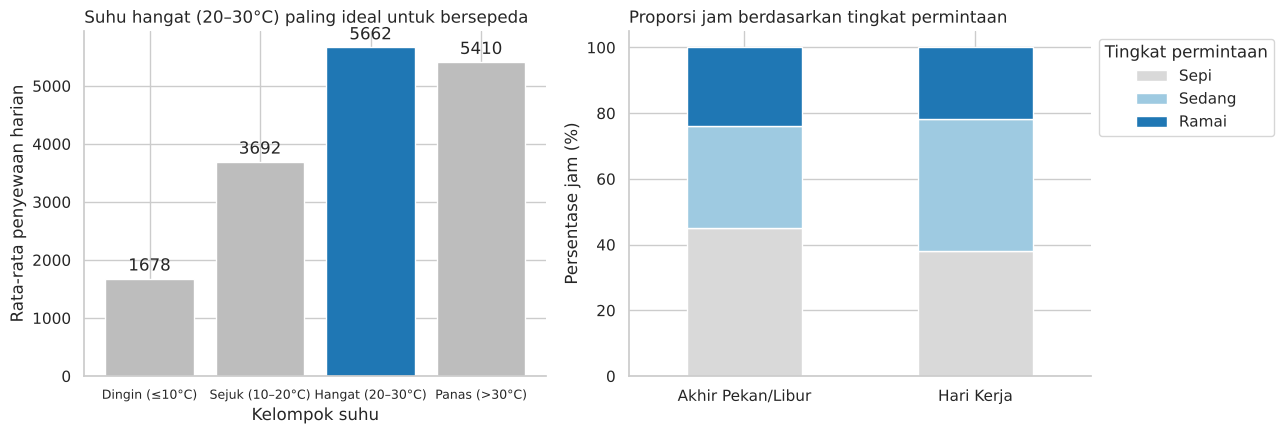

In [18]:
# 1. Binning suhu
bins = [-10, 10, 20, 30, 50]
labels = ["Dingin (≤10°C)", "Sejuk (10–20°C)", "Hangat (20–30°C)", "Panas (>30°C)"]
day_df["temp_group"] = pd.cut(day_df["temp_celsius"], bins=bins, labels=labels)
temp_group_stat = day_df.groupby("temp_group", observed=True)["cnt"].agg(["count", "mean"]).round(0)
print(temp_group_stat)

# 2. Manual grouping tingkat permintaan per jam
hour_df["demand_level"] = pd.cut(hour_df["cnt"], bins=[-1, 99, 300, 10000], labels=["Sepi", "Sedang", "Ramai"])
demand = hour_df.groupby(["day_type", "demand_level"], observed=True).size().unstack(fill_value=0)
demand_pct = (demand.div(demand.sum(axis=1), axis=0) * 100).round(1)
print("\nPersentase jam berdasarkan tingkat permintaan:")
print(demand_pct)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars = axes[0].bar(temp_group_stat.index.astype(str), temp_group_stat["mean"], color=["#bdbdbd", "#bdbdbd", "#1f77b4", "#bdbdbd"])
axes[0].bar_label(bars, fmt="%.0f", padding=3)
axes[0].set_title("Suhu hangat (20–30°C) paling ideal untuk bersepeda", loc="left", fontsize=12)
axes[0].set_xlabel("Kelompok suhu")
axes[0].set_ylabel("Rata-rata penyewaan harian")
axes[0].tick_params(axis="x", labelsize=9)

demand_pct[["Sepi", "Sedang", "Ramai"]].plot(kind="bar", stacked=True, ax=axes[1], color=["#d9d9d9", "#9ecae1", "#1f77b4"], rot=0)
axes[1].set_title("Proporsi jam berdasarkan tingkat permintaan", loc="left", fontsize=12)
axes[1].set_xlabel("")
axes[1].set_ylabel("Persentase jam (%)")
axes[1].legend(title="Tingkat permintaan", bbox_to_anchor=(1, 1))
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Penyewaan meningkat seiring suhu dan paling tinggi pada rentang hangat (20–30°C, sekitar 5.662 per hari). Pada suhu dingin (≤10°C) penyewaan jatuh ke sekitar 1.678 per hari.
- Pada suhu panas (>30°C) penyewaan sedikit menurun dibanding rentang hangat, meski jumlah harinya kecil (72 hari).
- Jam "Ramai" (>300 penyewaan) mencakup sekitar 21,7% jam pada hari kerja dan 23,9% pada akhir pekan/libur. Namun pada hari kerja jam ramai terkonsentrasi di jam komuting, sedangkan pada akhir pekan/libur tersebar di siang hari.

In [19]:
# Simpan data bersih untuk dashboard
import os
os.makedirs("dashboard", exist_ok=True)
hour_df.assign(demand_level=hour_df["demand_level"].astype(str)).to_csv("dashboard/main_data.csv", index=False)
day_df.assign(temp_group=day_df["temp_group"].astype(str)).to_csv("dashboard/day_data.csv", index=False)
print("Data bersih tersimpan di folder dashboard/")

Data bersih tersimpan di folder dashboard/


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Tiga jam puncak hari kerja adalah jam 17 (sekitar 525 penyewaan), jam 18 (sekitar 492), dan jam 8 (sekitar 477), yang membentuk dua puncak komuting (pagi dan sore). Tiga jam puncak akhir pekan/libur adalah jam 13, 12, dan 14 (sekitar 365–373 penyewaan) dengan pola satu puncak siang hari. Selisih terbesar ada pada jam 8: hari kerja lebih tinggi sekitar 371 sepeda (sekitar 4,5 kali lipat akhir pekan/libur), sedangkan pada jam 17–18 selisihnya sekitar 200–210 sepeda.
- **Conclusion pertanyaan 2:** Cuaca hujan/salju ringan menurunkan rata-rata penyewaan harian sekitar 63% dibanding cuaca cerah (1.803 vs 4.877). Musim Fall adalah musim tertinggi (sekitar 5.644 per hari) dan Spring terendah (sekitar 2.604 per hari).

**Rekomendasi Action Item:**
- Lakukan redistribusi sepeda ke stasiun area perkantoran dan permukiman sebelum jam 07.00 dan jam 16.00 pada hari kerja, serta tempatkan petugas lapangan pada jam 8 dan 17–18. Pada akhir pekan, geser fokus armada ke area wisata/taman pada jam 11.00–15.00.
- Jadwalkan perawatan armada besar pada musim/hari dengan permintaan rendah (Spring, suhu ≤10°C, dan hari hujan), serta fokuskan promosi dan penambahan armada pada musim Fall dan suhu hangat (20–30°C).
- Tawarkan promo atau diskon pada hari hujan/dingin untuk menjaga permintaan, serta integrasikan prakiraan cuaca ke dalam perencanaan operasional harian.